# F3.2 — Figuras de la primera pasada del grid (solo validación)

Figuras de apoyo de la tarea F3.2 (`results/f32_primera_pasada/README.md`, `docs/bitacora/F3.2.md`). Atienden la fila del plan *«F3.2–F3.5 (CE) | F1-Val por configuración con sus semillas; curvas de aprendizaje | Hacer transparente la selección del finalista»*. Las figuras 4–6 agregan trazabilidad de la parada temprana y de las predicciones que recibe SV. **No cambian resultados ni la selección**: la selección oficial de F3.3 la corre SV con `src/selection/select_finalist.py`.

Reglas que sigue este notebook:

- **Toda cifra de las gráficas se lee de archivos versionados:** `summary.csv` y `summary_by_config.csv` (F1-val por corrida y por configuración, marca `seleccion`) `runs/*.json` (historial por época) y `results/predictions/primera_pasada/*.csv` (predicciones F1.5). Las figuras 1–4 no recalculan métricas. Las figuras 5 y 6 cuentan predicciones a partir de `p_dep`, y antes se verifica que el F1-val que resulta coincide con el de los JSON.
- Solo validación: ninguna corrida cargó test (`grid_meta.json`, `f1_test` vacío). La celda de insumos lo verifica.
- Colores por técnica de `src/viz/style.py`; toda serie lleva etiqueta de texto (nunca solo color). PNG a 300 dpi en `results/f32_primera_pasada/figures/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():          # nbconvert ejecuta desde notebooks/
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'src'))
from viz import style

style.apply()
RES = REPO / 'results' / 'f32_primera_pasada'
V0 = REPO / 'results' / 'f32_primera_pasada_v0'
FIG = RES / 'figures'
TECHS = ['gray_scott', 'perlin', 'lorenz']          # orden de ejecucion del grid
ARCH_LABEL = {'resnet18': 'ResNet-18', 'efficientnet_b0': 'EfficientNet-B0', 'vit_b16': 'ViT-B/16'}
STRAT_LABEL = {'frozen': 'congelado', 'finetune': 'fine-tuning'}
SEL_LABEL = {'finalista_sugerido': 'finalista sugerido', 'empate_1std': 'empate (1 DE)'}

def cfg_label(arch, strategy):
    return f'{ARCH_LABEL[arch]} {STRAT_LABEL[strategy]}'

## Insumos

Se verifica que la carpeta es de la fase `primera_pasada`, que hay 54 corridas sin test y que `summary.csv` coincide con los JSON.

In [2]:
meta = json.loads((RES / 'grid_meta.json').read_text(encoding='utf-8'))
assert meta == {'fase': 'primera_pasada', 'smoke': False}, meta

runs = [json.loads(p.read_text(encoding='utf-8')) for p in sorted((RES / 'runs').glob('*.json'))]
assert len(runs) == 54
assert all(r['fase'] == 'primera_pasada' and r['f1_test'] is None and r['test_probs'] is None for r in runs)

summary = pd.read_csv(RES / 'summary.csv')
by_cfg = pd.read_csv(RES / 'summary_by_config.csv')
assert len(summary) == 54 and len(by_cfg) == 18 and summary.f1_test.isna().all()
for r in runs:
    row = summary[(summary.technique == r['technique']) & (summary.arch == r['arch'])
                  & (summary.strategy == r['strategy']) & (summary.seed == r['seed'])]
    assert len(row) == 1 and row.f1_val.item() == round(r['best_f1_val'], 4)
    assert row.best_epoch.item() == r['best_epoch'] and len(r['history']['f1_val']) == r['epochs_run']

print('commit', {r['git_commit'][:7] for r in runs}, '| variantes',
      {t: {r['variant'] for r in runs if r['technique'] == t} for t in TECHS})
by_cfg[['technique', 'arch', 'strategy', 'variant', 'n_trainable_params', 'f1_val_mean', 'f1_val_std', 'seleccion']]

commit {'36c6398'} | variantes {'gray_scott': {'px224-flip'}, 'perlin': {'px224-noflip'}, 'lorenz': {'px224-noflip'}}


,technique,arch,strategy,variant,n_trainable_params,f1_val_mean,f1_val_std,seleccion
0,gray_scott,resnet18,finetune,px224-flip,11177538,0.7197,0.0113,empate_1std
1,gray_scott,efficientnet_b0,finetune,px224-flip,4010110,0.7176,0.0125,finalista_sugerido
2,gray_scott,vit_b16,finetune,px224-flip,85800194,0.7175,0.0080,empate_1std
3,gray_scott,vit_b16,frozen,px224-flip,1538,0.7031,0.0104,NaN
4,gray_scott,efficientnet_b0,frozen,px224-flip,2562,0.6965,0.0021,NaN
5,gray_scott,resnet18,frozen,px224-flip,1026,0.6955,0.0093,NaN
6,perlin,vit_b16,frozen,px224-noflip,1538,0.7028,0.0073,finalista_sugerido
7,perlin,vit_b16,finetune,px224-noflip,85800194,0.6999,0.0203,empate_1std
8,perlin,efficientnet_b0,finetune,px224-noflip,4010110,0.6933,0.0137,NaN
9,perlin,efficientnet_b0,frozen,px224-noflip,2562,0.6918,0.0101,NaN


## Figura 1. F1-val por configuración, con sus semillas

Un panel por técnica. Cada fila es una configuración (arquitectura × estrategia), ordenada por F1-val medio. Los puntos huecos son las tres semillas (42, 7, 123; `summary.csv`); la barra es la media ± 1 DE con `ddof=1` (`summary_by_config.csv`). La banda sombreada va de *media del líder − DE del líder* a la media del líder: es la zona de empate de la regla de selección (matriz §5). Toda configuración cuya media cae dentro empata con el líder, y el empate lo rompe el menor número de parámetros entrenables (anotado a la derecha). La etiqueta en negritas es la marca `seleccion` del CSV.

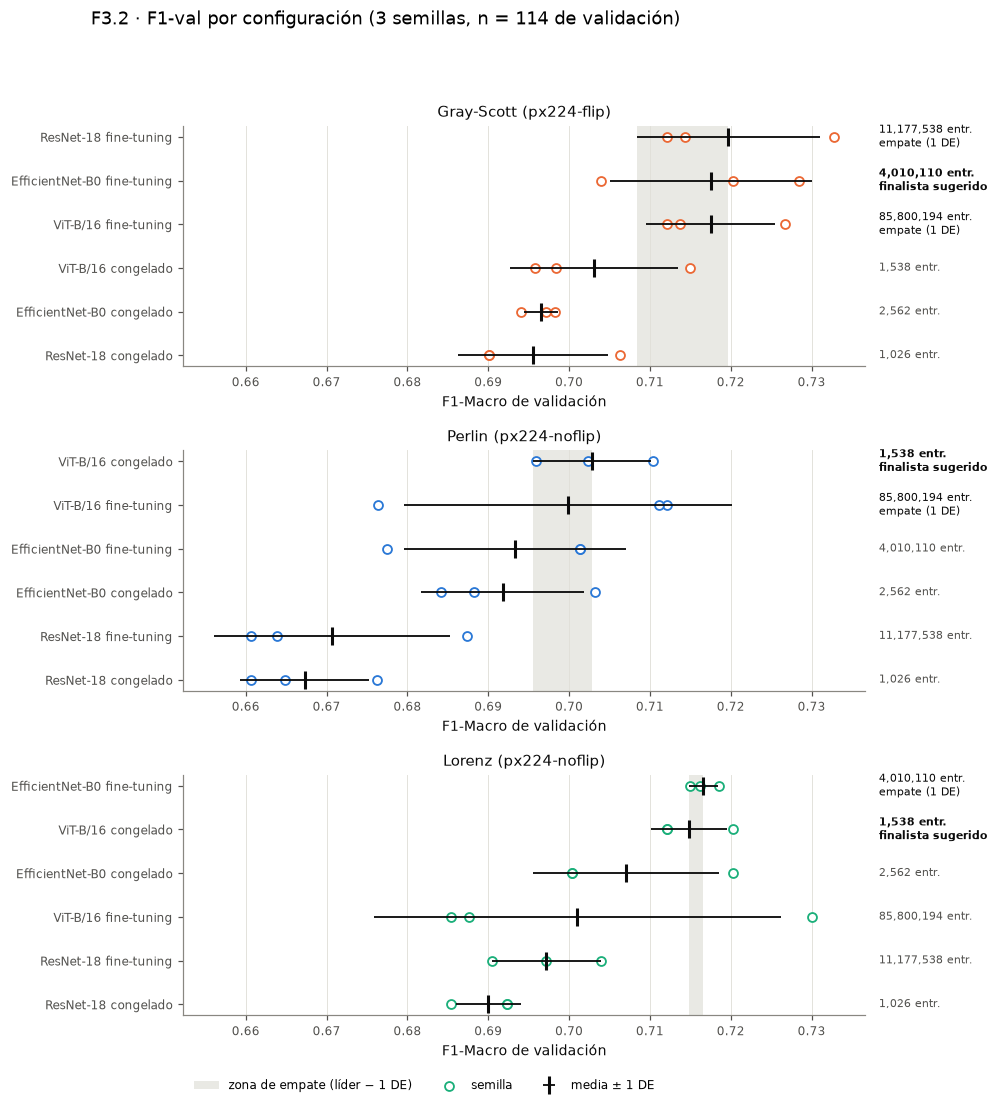

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(8, 10.5), sharex=True)
for ax, tech in zip(axes, TECHS):
    color = style.TECH_COLOR[tech]
    cfg = by_cfg[by_cfg.technique == tech].sort_values('f1_val_mean').reset_index(drop=True)
    leader = cfg.iloc[-1]
    ax.axvspan(leader.f1_val_mean - leader.f1_val_std, leader.f1_val_mean, color=style.GRID, alpha=0.7, lw=0,
               label='zona de empate (líder − 1 DE)')
    for y, c in cfg.iterrows():
        seeds = summary[(summary.technique == tech) & (summary.arch == c.arch) & (summary.strategy == c.strategy)]
        ax.scatter(seeds.f1_val, np.full(len(seeds), y), s=34, facecolors='white', edgecolors=color,
                   linewidths=1.2, zorder=3, label='semilla' if y == 0 else None)
        ax.errorbar(c.f1_val_mean, y, xerr=c.f1_val_std, fmt='|', color=style.INK, ms=12, mew=2,
                    elinewidth=1.2, capsize=0, zorder=4, label='media ± 1 DE' if y == 0 else None)
        sel = c.seleccion if isinstance(c.seleccion, str) else ''
        ax.text(1.02, y, f'{c.n_trainable_params:,} entr.' + (f'\n{SEL_LABEL[sel]}' if sel else ''),
                transform=ax.get_yaxis_transform(), va='center', fontsize=style.FONT_SIZES['annot'],
                color=style.INK if sel else style.INK_SECONDARY, fontweight='bold' if sel == 'finalista_sugerido' else None)
    ax.set_yticks(range(len(cfg)), [cfg_label(a, s) for a, s in zip(cfg.arch, cfg.strategy)])
    ax.set_title(f'{style.TECH_LABEL[tech]} ({leader.variant})', color=style.INK)
    ax.set_xlabel('F1-Macro de validación')
    ax.grid(axis='x')
    ax.set_axisbelow(True)
axes[-1].legend(loc='upper left', bbox_to_anchor=(0, -0.22), ncol=3)
fig.suptitle('F3.2 · F1-val por configuración (3 semillas, n = 114 de validación)', x=0.02, ha='left')
fig.subplots_adjust(hspace=0.35)
for ax in axes[:-1]:
    ax.tick_params(labelbottom=True)
style.save(fig, FIG / 'f1val_por_configuracion')
plt.show()

## Figura 2. Curvas de aprendizaje

Una figura por técnica: arriba, F1-val por época; abajo, pérdida de entrenamiento (CE con pesos de clase). Columnas: las seis configuraciones; una línea por semilla (`history` de `runs/*.json`). El punto marca la mejor época por F1-val, que es el modelo que se guarda; la línea termina donde actuó la parada temprana (paciencia 4, máximo 15 épocas). Las líneas de una misma técnica comparten color y se distinguen por trazo y por la leyenda.

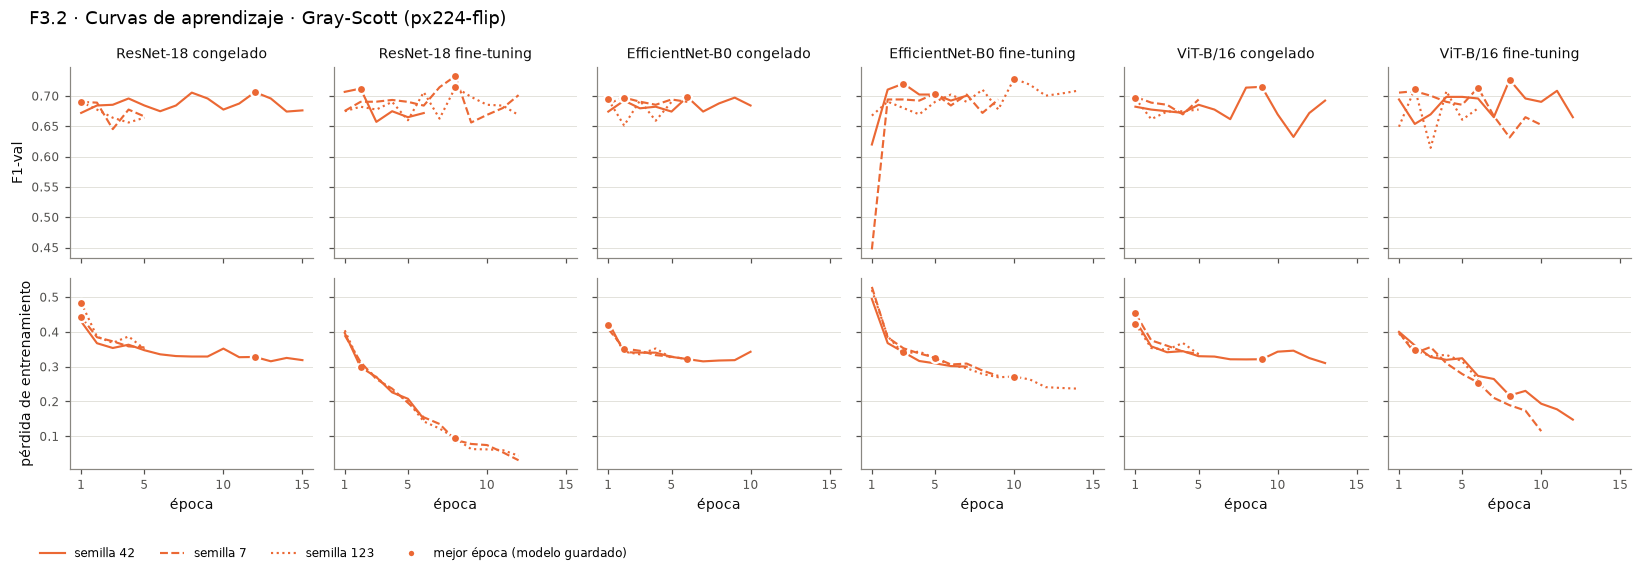

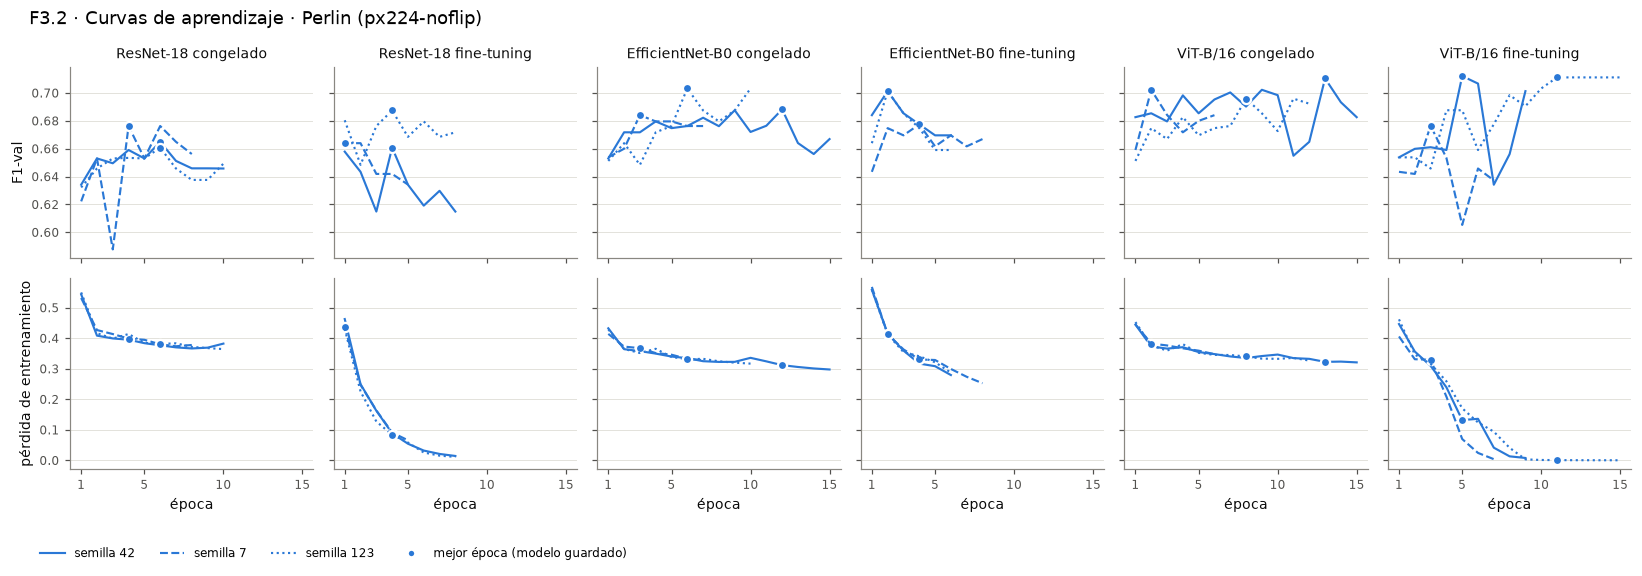

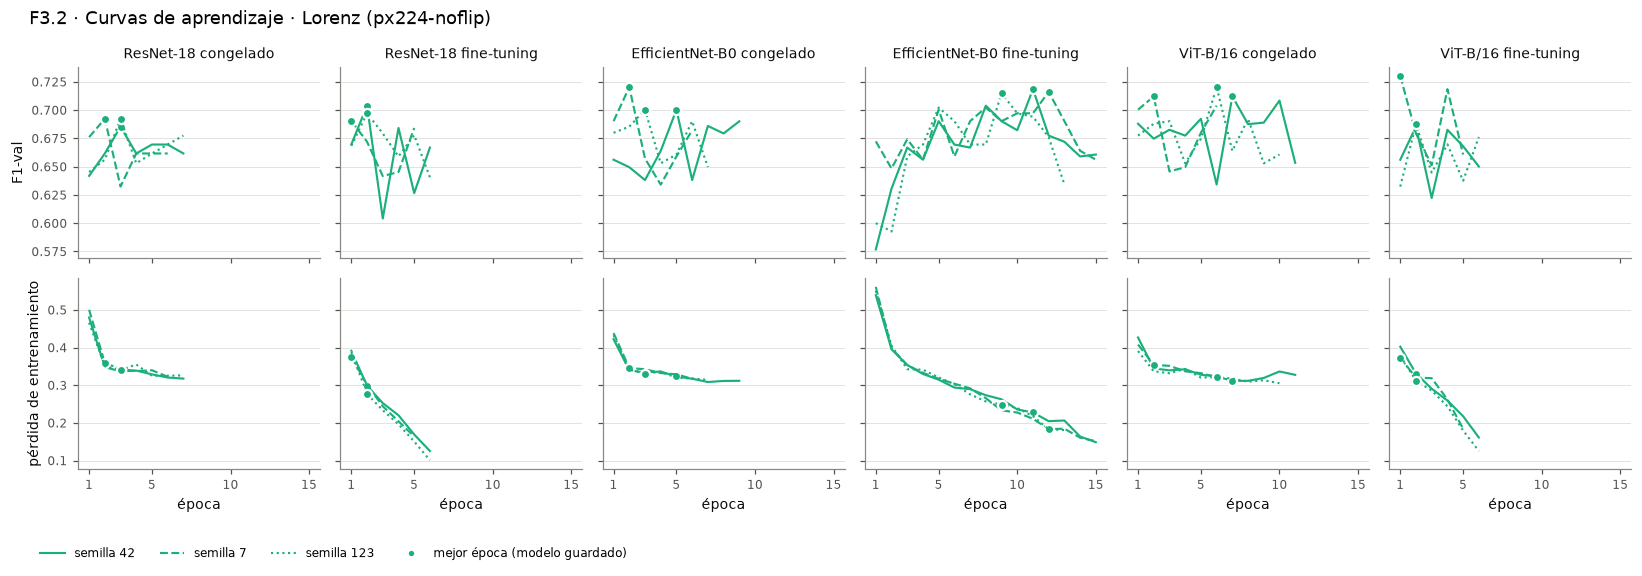

In [4]:
SEED_STYLE = {42: '-', 7: '--', 123: ':'}
CONFIGS = [(a, s) for a in ARCH_LABEL for s in ('frozen', 'finetune')]

def learning_curves(tech):
    color = style.TECH_COLOR[tech]
    fig, axes = plt.subplots(2, 6, figsize=(15, 5), sharex=True, sharey='row')
    for j, (arch, strat) in enumerate(CONFIGS):
        for r in sorted((r for r in runs if r['technique'] == tech and r['arch'] == arch and r['strategy'] == strat),
                        key=lambda r: list(SEED_STYLE).index(r['seed'])):
            ep = np.arange(1, r['epochs_run'] + 1)
            for i, key in enumerate(('f1_val', 'train_loss')):
                axes[i, j].plot(ep, r['history'][key], SEED_STYLE[r['seed']], color=color, lw=1.4,
                                label=f"semilla {r['seed']}")
                b = r['best_epoch']
                axes[i, j].plot(b, r['history'][key][b - 1], 'o', ms=6, color=color, mec='white', mew=1.5)
        axes[0, j].set_title(cfg_label(arch, strat), fontsize=style.FONT_SIZES['label'])
        axes[1, j].set_xlabel('época')
        for ax in axes[:, j]:
            ax.grid(axis='y')
            ax.set_axisbelow(True)
            ax.set_xticks([1, 5, 10, 15])
    axes[0, 0].set_ylabel('F1-val')
    axes[1, 0].set_ylabel('pérdida de entrenamiento')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    handles.append(plt.Line2D([], [], marker='o', ls='', color=color, mec='white', mew=1.5))
    labels.append('mejor época (modelo guardado)')
    fig.legend(handles, labels, loc='lower left', ncol=4, bbox_to_anchor=(0.02, -0.04))
    variant = by_cfg.loc[by_cfg.technique == tech, 'variant'].iloc[0]
    fig.suptitle(f'F3.2 · Curvas de aprendizaje · {style.TECH_LABEL[tech]} ({variant})', x=0.02, ha='left')
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig

for tech in TECHS:
    fig = learning_curves(tech)
    style.save(fig, FIG / f'curvas_aprendizaje_{tech}')
    plt.show()

## Figura 3. Primera pasada v0 frente a la repetición

F1-val medio por configuración en la v0 (21 oct 2026, `results/f32_primera_pasada_v0/summary_by_config.csv`) y en la repetición (`summary_by_config.csv`). **No son el mismo experimento en las tres técnicas:**

- **Gray-Scott:** misma variante (`px224-flip`). Cambian el optimizador nominal (Adam → AdamW con `weight_decay=0`, equivalentes), los ajustes de determinismo y la imagen de Kaggle (cu128 → cu130).
- **Perlin y Lorenz:** además cambia el preprocesamiento (`px224-flip` → `px224-noflip`, F1.4 H6/H7).

Si en una fila no se ve el punto hueco, el valor de la v0 coincide con el de la repetición. La figura sirve para ver cuánto se movió cada configuración y si cambió el finalista sugerido. No es una comparación confirmatoria.

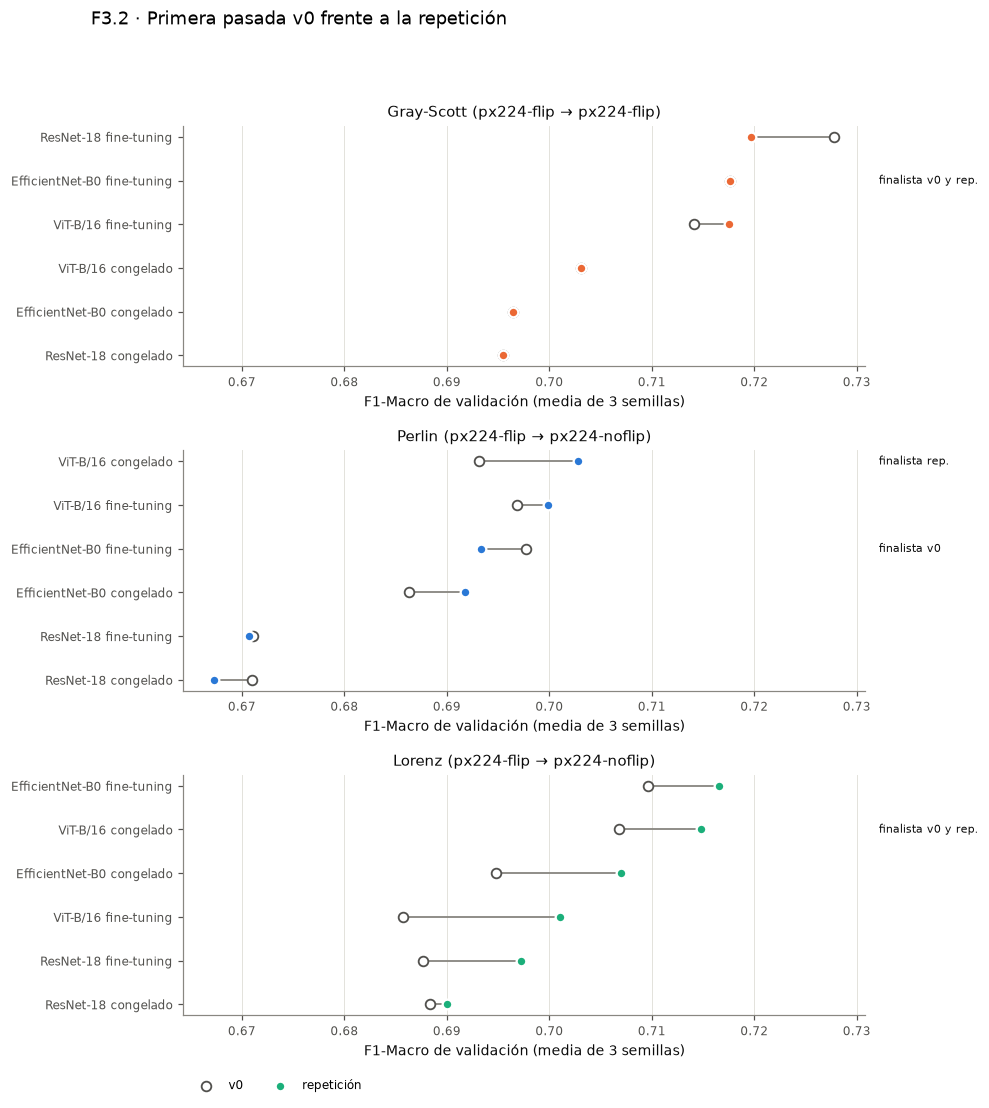

,technique,arch,strategy,variant_v0,variant,f1_val_mean_v0,f1_val_mean,seleccion_v0,seleccion
0,gray_scott,resnet18,finetune,px224-flip,px224-flip,0.7278,0.7197,empate_1std,empate_1std
1,gray_scott,efficientnet_b0,finetune,px224-flip,px224-flip,0.7176,0.7176,finalista_sugerido,finalista_sugerido
2,gray_scott,vit_b16,finetune,px224-flip,px224-flip,0.7141,0.7175,empate_1std,empate_1std
3,gray_scott,vit_b16,frozen,px224-flip,px224-flip,0.7031,0.7031,NaN,NaN
4,gray_scott,efficientnet_b0,frozen,px224-flip,px224-flip,0.6965,0.6965,NaN,NaN
5,gray_scott,resnet18,frozen,px224-flip,px224-flip,0.6955,0.6955,NaN,NaN
6,perlin,vit_b16,frozen,px224-flip,px224-noflip,0.6931,0.7028,NaN,finalista_sugerido
7,perlin,vit_b16,finetune,px224-flip,px224-noflip,0.6968,0.6999,empate_1std,empate_1std
8,perlin,efficientnet_b0,finetune,px224-flip,px224-noflip,0.6977,0.6933,finalista_sugerido,NaN
9,perlin,efficientnet_b0,frozen,px224-flip,px224-noflip,0.6863,0.6918,NaN,NaN


In [5]:
v0 = pd.read_csv(V0 / 'summary_by_config.csv').replace({'arch': {'vit_b_16': 'vit_b16'}})
both = by_cfg.merge(v0, on=['technique', 'arch', 'strategy'], suffixes=('', '_v0'))
assert len(both) == 18

fig, axes = plt.subplots(3, 1, figsize=(8, 10.5), sharex=True)
for ax, tech in zip(axes, TECHS):
    color = style.TECH_COLOR[tech]
    d = both[both.technique == tech].sort_values('f1_val_mean').reset_index(drop=True)
    for y, c in d.iterrows():
        ax.plot([c.f1_val_mean_v0, c.f1_val_mean], [y, y], color=style.MUTED, lw=1.2, zorder=2)
        ax.scatter(c.f1_val_mean_v0, y, s=40, facecolors='white', edgecolors=style.INK_SECONDARY, linewidths=1.2,
                   zorder=3, label='v0' if y == 0 else None)
        ax.scatter(c.f1_val_mean, y, s=40, color=color, edgecolors='white', linewidths=1.5, zorder=4,
                   label='repetición' if y == 0 else None)
        marks = [m for m, s in (('v0', c.seleccion_v0), ('rep.', c.seleccion)) if s == 'finalista_sugerido']
        if marks:
            ax.text(1.02, y, 'finalista ' + ' y '.join(marks), transform=ax.get_yaxis_transform(), va='center',
                    fontsize=style.FONT_SIZES['annot'], color=style.INK)
    ax.set_yticks(range(len(d)), [cfg_label(a, s) for a, s in zip(d.arch, d.strategy)])
    ax.set_title(f"{style.TECH_LABEL[tech]} ({d.variant_v0.iloc[0]} → {d.variant.iloc[0]})")
    ax.set_xlabel('F1-Macro de validación (media de 3 semillas)')
    ax.grid(axis='x')
    ax.set_axisbelow(True)
axes[-1].legend(loc='upper left', bbox_to_anchor=(0, -0.22), ncol=2)
fig.suptitle('F3.2 · Primera pasada v0 frente a la repetición', x=0.02, ha='left')
fig.subplots_adjust(hspace=0.35)
for ax in axes[:-1]:
    ax.tick_params(labelbottom=True)
style.save(fig, FIG / 'v0_vs_repeticion')
plt.show()

both[['technique', 'arch', 'strategy', 'variant_v0', 'variant', 'f1_val_mean_v0', 'f1_val_mean', 'seleccion_v0', 'seleccion']]

## Figura 4. Parada temprana

Para cada corrida, el punto marca la mejor época por F1-val (el modelo guardado) y la línea llega hasta la última época corrida. Con paciencia 4 y un máximo de 15 épocas (`configs/matriz_experimentos.json`, `configuracion_comun`), una corrida que termina en la época 15 con mejor época ≥ 12 **la detuvo el tope, no la paciencia**: no se sabe si habría mejorado con más épocas. Esas corridas se marcan con ✕ y se cuentan en el título de cada panel. F3.4 deja fijas las épocas máximas (matriz §6), así que este conteo es lo que permite ver si el tope pesa en algún finalista.

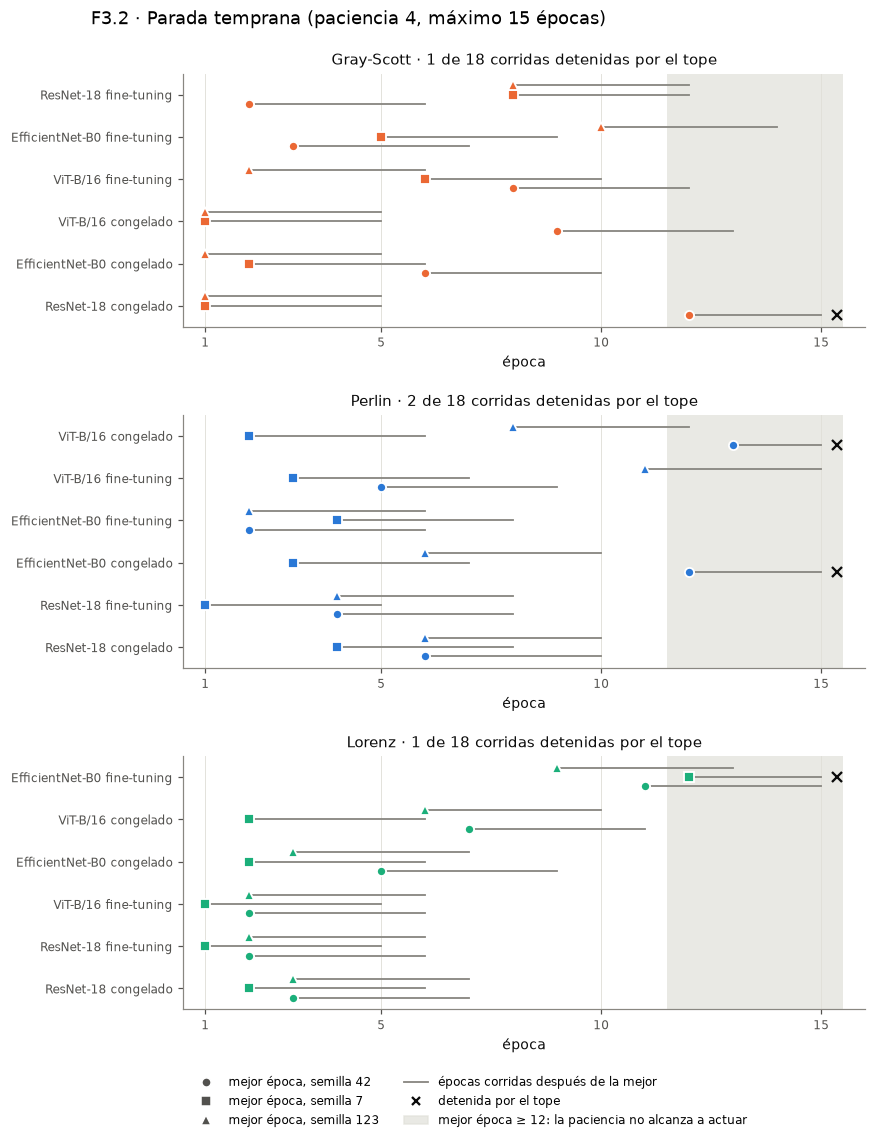

,technique,arch,strategy,seed,best_epoch,epochs_run,f1_val
10,gray_scott,resnet18,frozen,42,12,15,0.7063
22,perlin,efficientnet_b0,frozen,42,12,15,0.6882
34,perlin,vit_b16,frozen,42,13,15,0.7104
36,lorenz,efficientnet_b0,finetune,7,12,15,0.7162


In [6]:
matriz = json.loads((REPO / 'configs' / 'matriz_experimentos.json').read_text(encoding='utf-8'))
MAX_EP = matriz['configuracion_comun']['max_epochs']
PATIENCE = matriz['configuracion_comun']['early_stopping']['patience']
SEEDS = [42, 7, 123]
SEED_OFFSET = {42: -0.22, 7: 0.0, 123: 0.22}
SEED_MARKER = {42: 'o', 7: 's', 123: '^'}

summary['por_tope'] = (summary.epochs_run == MAX_EP) & (summary.best_epoch > MAX_EP - PATIENCE)

fig, axes = plt.subplots(3, 1, figsize=(8, 10.5), sharex=True)
for ax, tech in zip(axes, TECHS):
    color = style.TECH_COLOR[tech]
    cfg = by_cfg[by_cfg.technique == tech].sort_values('f1_val_mean').reset_index(drop=True)
    ax.axvspan(MAX_EP - PATIENCE + 0.5, MAX_EP + 0.5, color=style.GRID, alpha=0.7, lw=0,
               label=f'mejor época ≥ {MAX_EP - PATIENCE + 1}: la paciencia no alcanza a actuar')
    for y, c in cfg.iterrows():
        for _, r in summary[(summary.technique == tech) & (summary.arch == c.arch)
                            & (summary.strategy == c.strategy)].iterrows():
            yy = y + SEED_OFFSET[r.seed]
            ax.plot([r.best_epoch, r.epochs_run], [yy, yy], color=style.MUTED, lw=1.2, zorder=2)
            ax.plot(r.best_epoch, yy, SEED_MARKER[r.seed], ms=6, color=color, mec='white', mew=1.2, zorder=3)
            if r.por_tope:
                ax.plot(r.epochs_run + 0.35, yy, 'x', ms=6, color=style.INK, mew=1.5, zorder=4)
    n_tope = int(summary[(summary.technique == tech)].por_tope.sum())
    ax.set_yticks(range(len(cfg)), [cfg_label(a, s) for a, s in zip(cfg.arch, cfg.strategy)])
    ax.set_title(f'{style.TECH_LABEL[tech]} · {n_tope} de 18 corridas detenidas por el tope')
    ax.set_xlim(0.5, MAX_EP + 1)
    ax.set_xticks([1, 5, 10, MAX_EP])
    ax.set_xlabel('época')
    ax.grid(axis='x')
    ax.set_axisbelow(True)
handles = [plt.Line2D([], [], marker=SEED_MARKER[s], ls='', color=style.INK_SECONDARY, mec='white', ms=6,
                      label=f'mejor época, semilla {s}') for s in SEEDS]
handles += [plt.Line2D([], [], color=style.MUTED, lw=1.2, label='épocas corridas después de la mejor'),
            plt.Line2D([], [], marker='x', ls='', color=style.INK, mew=1.5, label='detenida por el tope'),
            plt.Rectangle((0, 0), 1, 1, color=style.GRID, alpha=0.7, label=axes[0].get_legend_handles_labels()[1][0])]
axes[-1].legend(handles=handles, loc='upper left', bbox_to_anchor=(0, -0.22), ncol=2)
fig.suptitle(f'F3.2 · Parada temprana (paciencia {PATIENCE}, máximo {MAX_EP} épocas)', x=0.02, y=0.975, ha='left')
fig.subplots_adjust(hspace=0.35, top=0.92)
for ax in axes[:-1]:
    ax.tick_params(labelbottom=True)
style.save(fig, FIG / 'parada_temprana')
plt.show()

summary.loc[summary.por_tope, ['technique', 'arch', 'strategy', 'seed', 'best_epoch', 'epochs_run', 'f1_val']]

## Predicciones de los candidatos

Las figuras 5 y 6 usan las predicciones F1.5 de los **candidatos de F3.3**: las configuraciones con marca `seleccion` en `summary_by_config.csv`, es decir, el finalista sugerido y las que empatan con el líder. Se cargan las tres semillas de cada una. `p_dep` se lee con `float_precision='round_trip'` para no perder precisión, y la predicción es `y_hat = 1` si y solo si `p_dep > 0.5` (F1.5 §3.3). La celda verifica que el F1-val que resulta de esas predicciones coincide con el `best_f1_val` del JSON de cada corrida.

In [7]:
PRED = REPO / 'results' / 'predictions' / 'primera_pasada'

def f1_macro(y, y_hat):
    f1 = []
    for k in (0, 1):
        tp = np.sum((y_hat == k) & (y == k))
        fp = np.sum((y_hat == k) & (y != k))
        fn = np.sum((y_hat != k) & (y == k))
        f1.append(2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f1))

cand = by_cfg[by_cfg.seleccion.notna()].copy()
cand['orden'] = cand.technique.map(TECHS.index)
cand = cand.sort_values(['orden', 'f1_val_mean'], ascending=[True, False]).reset_index(drop=True)

PREDS = {}
for _, c in cand.iterrows():
    frames = [pd.read_csv(PRED / f'{c.technique}__{c.arch}__{c.strategy}__seed{s}.csv', float_precision='round_trip')
              for s in SEEDS]
    df = pd.concat(frames)
    assert (df.split == 'val').all() and df.groupby('seed').size().eq(114).all()
    P = df.pivot(index='sample_id', columns='seed', values='p_dep')[SEEDS]
    y = df.groupby('sample_id').y_true.first().loc[P.index]
    Y_hat = (P.to_numpy() > 0.5).astype(int)
    for j, s in enumerate(SEEDS):
        run = next(r for r in runs if (r['technique'], r['arch'], r['strategy'], r['seed'])
                   == (c.technique, c.arch, c.strategy, s))
        assert np.isclose(f1_macro(y.to_numpy(), Y_hat[:, j]), run['best_f1_val'], rtol=0, atol=1e-12)
    PREDS[(c.technique, c.arch, c.strategy)] = (P, y.to_numpy(), Y_hat)

cand[['technique', 'arch', 'strategy', 'n_trainable_params', 'f1_val_mean', 'f1_val_std', 'seleccion']]

,technique,arch,strategy,n_trainable_params,f1_val_mean,f1_val_std,seleccion
0,gray_scott,resnet18,finetune,11177538,0.7197,0.0113,empate_1std
1,gray_scott,efficientnet_b0,finetune,4010110,0.7176,0.0125,finalista_sugerido
2,gray_scott,vit_b16,finetune,85800194,0.7175,0.0080,empate_1std
3,perlin,vit_b16,frozen,1538,0.7028,0.0073,finalista_sugerido
4,perlin,vit_b16,finetune,85800194,0.6999,0.0203,empate_1std
5,lorenz,efficientnet_b0,finetune,4010110,0.7166,0.0018,empate_1std
6,lorenz,vit_b16,frozen,1538,0.7148,0.0047,finalista_sugerido


## Figura 5. Distribución de `p_dep` y matriz de confusión

Una fila por candidato. **Izquierda:** histograma de `p_dep` por clase real, con las tres semillas juntas (3 × 114 = 342 predicciones por fila). La línea discontinua es el umbral 0.5. Un modelo que separa las clases empuja la clase depresiva a la derecha y la no depresiva a la izquierda; si las dos distribuciones se amontonan cerca del umbral, el modelo apenas discrimina. **Derecha:** matriz de confusión con la media de las tres semillas. El número de cada celda es el conteo medio y el tono es la proporción por fila (clase real). Arriba se indica la tasa de falsos negativos (depresivos clasificados como no depresivos), la métrica que más importa clínicamente.

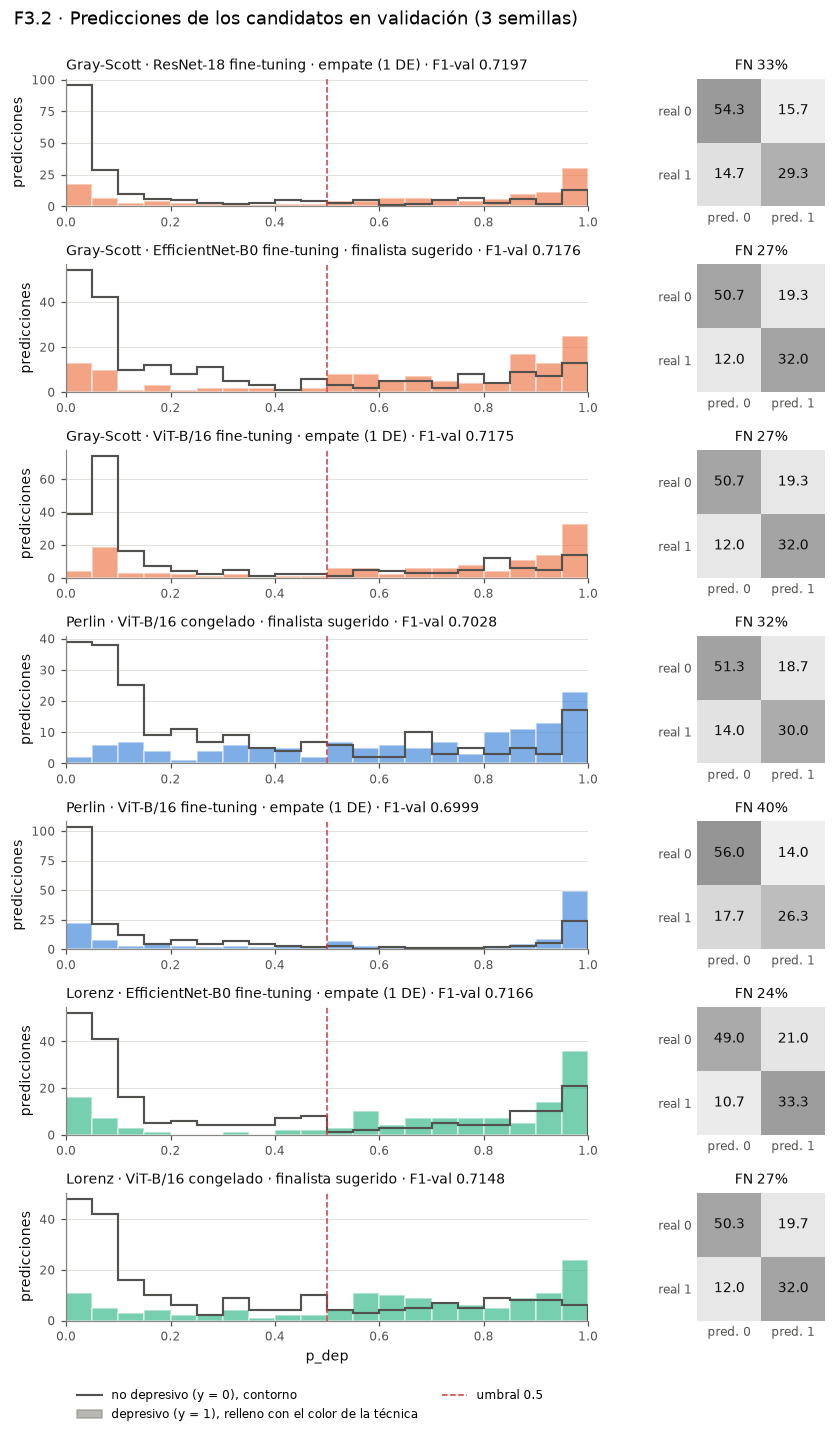

In [8]:
bins = np.linspace(0, 1, 21)
fig, axes = plt.subplots(len(cand), 2, figsize=(8, 1.85 * len(cand) + 0.8),
                         gridspec_kw={'width_ratios': [3, 1.15]})
for i, c in cand.iterrows():
    P, y, Y_hat = PREDS[(c.technique, c.arch, c.strategy)]
    color = style.TECH_COLOR[c.technique]
    ax = axes[i, 0]
    ax.hist(P.to_numpy()[y == 0].ravel(), bins=bins, histtype='step', color=style.INK_SECONDARY, lw=1.4,
            label='no depresivo (y = 0)')
    ax.hist(P.to_numpy()[y == 1].ravel(), bins=bins, color=color, alpha=0.6, edgecolor=style.SURFACE, lw=1,
            label='depresivo (y = 1)')
    ax.axvline(0.5, color=style.THRESHOLD_COLOR, lw=1, ls='--', label='umbral 0.5')
    ax.set_xlim(0, 1)
    ax.set_title(f'{style.TECH_LABEL[c.technique]} · {cfg_label(c.arch, c.strategy)} · {SEL_LABEL[c.seleccion]}'
                 f' · F1-val {c.f1_val_mean:.4f}', loc='left', fontsize=style.FONT_SIZES['label'])
    ax.set_ylabel('predicciones')
    ax.grid(axis='y')
    ax.set_axisbelow(True)
    if i == len(cand) - 1:
        ax.set_xlabel('p_dep')

    cm = np.array([[np.sum((y[:, None] == t) & (Y_hat == p)) for p in (0, 1)] for t in (0, 1)]) / len(SEEDS)
    ax = axes[i, 1]
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap='Greys', vmin=0, vmax=1.6)
    for t in (0, 1):
        for p in (0, 1):
            ax.text(p, t, f'{cm[t, p]:.1f}', ha='center', va='center', color=style.INK,
                    fontsize=style.FONT_SIZES['label'])
    ax.set_xticks([0, 1], ['pred. 0', 'pred. 1'])
    ax.set_yticks([0, 1], ['real 0', 'real 1'])
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f'FN {cm[1, 0] / cm[1].sum():.0%}', fontsize=style.FONT_SIZES['label'])
axes[-1, 0].legend(handles=[
    plt.Line2D([], [], color=style.INK_SECONDARY, lw=1.4, label='no depresivo (y = 0), contorno'),
    plt.Rectangle((0, 0), 1, 1, color=style.MUTED, alpha=0.6, label='depresivo (y = 1), relleno con el color de la técnica'),
    plt.Line2D([], [], color=style.THRESHOLD_COLOR, lw=1, ls='--', label='umbral 0.5')],
    loc='upper left', bbox_to_anchor=(0, -0.45), ncol=2)
fig.suptitle('F3.2 · Predicciones de los candidatos en validación (3 semillas)', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0.03, 1, 0.98))
style.save(fig, FIG / 'predicciones_candidatos')
plt.show()

## Figura 6. Acuerdo entre semillas

Para cada candidato y cada muestra de validación se cuenta en cuántas de las tres semillas la predicción es correcta. La barra reparte las 114 muestras en 3/3, 2/3, 1/3 y 0/3 aciertos. Las muestras con 3/3 o 0/3 son **unánimes**: las tres semillas predicen lo mismo, y su suma se anota a la derecha. Dos configuraciones pueden tener el mismo F1 medio con acuerdo muy distinto. Si el acuerdo es bajo, la semilla decide buena parte de las predicciones, y eso pesa en las pruebas pareadas de las Fases 4 y 5. Las muestras con 0/3 son errores sistemáticos: todas las semillas fallan en ellas.

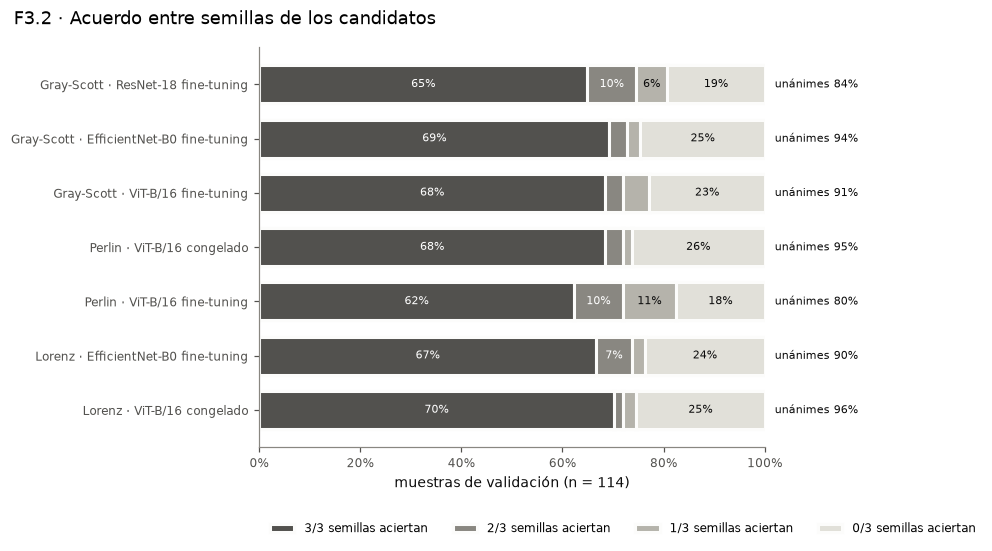

,technique,arch,strategy,seleccion,aciertan_3de3,aciertan_2de3,aciertan_1de3,aciertan_0de3,unanimes
0,gray_scott,resnet18,finetune,empate_1std,74,11,7,22,0.842105
1,gray_scott,efficientnet_b0,finetune,finalista_sugerido,79,4,3,28,0.938596
2,gray_scott,vit_b16,finetune,empate_1std,78,4,6,26,0.912281
3,perlin,vit_b16,frozen,finalista_sugerido,78,4,2,30,0.947368
4,perlin,vit_b16,finetune,empate_1std,71,11,12,20,0.798246
5,lorenz,efficientnet_b0,finetune,empate_1std,76,8,3,27,0.903509
6,lorenz,vit_b16,frozen,finalista_sugerido,80,2,3,29,0.956140


In [9]:
RAMP = {0: '#e1e0d9', 1: '#b5b3ab', 2: '#898781', 3: '#52514e'}   # aciertos de 0 a 3, claro a oscuro
TEXT_ON = {0: style.INK, 1: style.INK, 2: 'white', 3: 'white'}

fig, ax = plt.subplots(figsize=(8, 0.5 * len(cand) + 1.6))
rows = []
for i, c in cand.iterrows():
    P, y, Y_hat = PREDS[(c.technique, c.arch, c.strategy)]
    k = (Y_hat == y[:, None]).sum(axis=1)
    frac = {n: float(np.mean(k == n)) for n in (3, 2, 1, 0)}
    left = 0.0
    for n, f in frac.items():
        ax.barh(i, f, left=left, color=RAMP[n], edgecolor=style.SURFACE, lw=2, height=0.7,
                label=f'{n}/3 semillas aciertan' if i == 0 else None)
        if f >= 0.06:
            ax.text(left + f / 2, i, f'{f:.0%}', ha='center', va='center', color=TEXT_ON[n],
                    fontsize=style.FONT_SIZES['annot'])
        left += f
    unan = frac[3] + frac[0]
    ax.text(1.02, i, f'unánimes {unan:.0%}', transform=ax.get_yaxis_transform(), va='center',
            fontsize=style.FONT_SIZES['annot'], color=style.INK)
    rows.append({'technique': c.technique, 'arch': c.arch, 'strategy': c.strategy, 'seleccion': c.seleccion,
                 **{f'aciertan_{n}de3': int(np.sum(k == n)) for n in (3, 2, 1, 0)}, 'unanimes': unan})
ax.set_yticks(range(len(cand)), [f'{style.TECH_LABEL[t]} · {cfg_label(a, s)}'
                                 for t, a, s in zip(cand.technique, cand.arch, cand.strategy)])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('muestras de validación (n = 114)')
ax.grid(False)
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.16), ncol=4)
fig.suptitle('F3.2 · Acuerdo entre semillas de los candidatos', x=0.02, ha='left')
fig.tight_layout()
style.save(fig, FIG / 'acuerdo_semillas')
plt.show()

pd.DataFrame(rows)